# Part 1 — Data, split and map (Jason)

Builds the shared modeling table and the artist-grouped split, runs the two baselines, the t-SNE map and the
genre-control check.

| Output | Used by |
|---|---|
| `data/model_data.parquet`, `data/split.csv` | everyone (Parts 2 and 3) |
| `outputs/cv_scores.csv` (Baseline + LogReg rows) | Ashritha adds RF + GBM; visual #3 |
| `outputs/tsne_coords.csv`, `outputs/fig2_tsne_era.png` | visual #2, Dash app |
| `outputs/genre_control.csv` | report (1.4) |

In [1]:
import sys; from pathlib import Path
# repo root = first folder up from here that has src/style.py (works wherever Jupyter was started)
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "style.py").exists())))
from src.style import *

import time
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.manifold import TSNE
from lightgbm import LGBMClassifier

OUT_DIR.mkdir(exist_ok=True)

## 1.1 Modeling table

Sound features only. Popularity, followers and year would leak the era.

In [2]:
clean = load_clean()
model_df = make_model_table(clean)

LEAKY = {"popularity", "artist_followers", "artist_popularity", "year", "release_year", "decade", "artist_debut_year"}
assert not LEAKY & set(FEATURES), "a leaky column is in FEATURES"

print(f"{len(model_df):,} tracks x {len(FEATURES)} sound features, {model_df.artist_id.nunique():,} artists")
print("Missing values (median-imputed inside each pipeline):",
      model_df[FEATURES].isna().sum()[lambda s: s > 0].to_dict())
model_df.head()

526,608 tracks x 13 sound features, 71,492 artists
Missing values (median-imputed inside each pipeline): {'loudness': 202, 'tempo': 301, 'time_signature': 309}


,id,name,artist_id,year,era,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,key,mode,time_signature
0,0004Uy71ku11n3LMpuyf59,24.11.94 - Wersja Akustyczna,3NyQ2NjqMjDtVSiEkXFW2r,2012,3,0.623,0.599,-9.255,0.0255,0.1770,0.001480,0.0748,0.381,140.056,258907.0,6.0,1.0,4.0
1,000CSYu4rvd8cQ7JilfxhZ,Adam et Ève,1KMHmX2PgvEl1nFzFmEdcZ,2005,3,0.624,0.766,-7.860,0.0731,0.3450,0.000000,0.1130,0.548,95.128,189107.0,2.0,1.0,4.0
2,000DsoWJKHdaUmhgcnpr8j,Balla Trazan Apansson / Vegetarianvisan,5PbCQPKjb0wQwaE7i5OVC6,1977,1,0.572,0.608,-10.224,0.5550,0.6420,0.000220,0.3440,0.559,106.453,234533.0,7.0,1.0,4.0
3,000G1xMMuwxNHmwVsBdtj1,Will Anything Happen,4tpUmLEVLCGFr93o8hFFIB,1978,1,0.256,0.895,-4.860,0.0707,0.0131,0.000106,0.0821,0.555,191.307,182347.0,2.0,1.0,4.0
4,000KblXP5csWFFFsD6smOy,Podrás,11PnNvuse5a0xPupBIeHyW,2006,3,0.619,0.518,-5.392,0.0534,0.8050,0.000000,0.1020,0.314,143.757,240013.0,4.0,0.0,3.0


## 1.2 Artist-grouped split (80/20) + CV folds

Fold 0 of `StratifiedGroupKFold(5)` is the test set (~20% of artists); the training rows get folds 0–4 for CV.
The assert inside `make_split` proves no artist is in both.

In [3]:
split_df = make_split(model_df)
check_split(split_df)

split_df[["id", "split", "fold"]].to_csv(SPLIT_PATH, index=False)
model_df.to_parquet(MODEL_DATA_PATH, index=False)
print(f"\nWrote {SPLIT_PATH.name} and {MODEL_DATA_PATH.name}")

rows: 526608
split
train    426629
test      99979 

fold
-1    99979
 0    83406
 1    86747
 2    85825
 3    82376
 4    88275 

era    Pre-1960  1960–79  1980–99  2000+
split                                   
test      0.125    0.197    0.309  0.369
train     0.127    0.188    0.334  0.351



Wrote split.csv and model_data.parquet


## 1.5 Baselines: Dummy + Logistic Regression

Same models as 2.2 and the same locked folds as 2.3, so Ashritha's RF/GBM scores are directly comparable.
Results go to `outputs/cv_scores.csv` in long format: one row per model per fold.

In [4]:
train = split_df[split_df.split == "train"].reset_index(drop=True)
cv = PredefinedSplit(train["fold"])                       # the locked folds
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

baselines = {
    "Baseline": DummyClassifier(strategy="stratified", random_state=SEED),
    "LogReg":   make_pipeline(prep, LogisticRegression(max_iter=2000, class_weight="balanced")),
}

rows = []
for name, model in baselines.items():
    t0 = time.time()
    s = cross_val_score(model, train[FEATURES], train.era, cv=cv, scoring="f1_macro", n_jobs=5)
    rows += [{"model": name, "fold": k, "f1_macro": v} for k, v in enumerate(s)]
    print(f"{name:<9} macro-F1 = {s.mean():.3f} ± {s.std():.3f}   ({time.time() - t0:.0f}s)")

# Reference only (not saved): always predicting the biggest era
mf = cross_val_score(DummyClassifier(strategy="most_frequent"), train[FEATURES], train.era,
                     cv=cv, scoring="f1_macro")
print(f"(most-frequent dummy, for reference: {mf.mean():.3f})")

# Upsert: replace any old rows for these models, keep everyone else's
cv_path = OUT_DIR / "cv_scores.csv"
new = pd.DataFrame(rows)
if cv_path.exists():
    old = pd.read_csv(cv_path)
    new = pd.concat([old[~old.model.isin(baselines)], new], ignore_index=True)
new.to_csv(cv_path, index=False)
new.groupby("model").f1_macro.agg(["mean", "std"]).round(3)

Baseline  macro-F1 = 0.249 ± 0.001   (2s)


LogReg    macro-F1 = 0.518 ± 0.011   (2s)
(most-frequent dummy, for reference: 0.130)


,mean,std
model,,
Baseline,0.249,0.001
LogReg,0.518,0.012


## 1.3 t-SNE map

15k tracks, 3,750 per era. Standardize first so `duration_ms` doesn't dominate distances.
Settings from lecture: perplexity 30, 1,000 iterations, seed 42.

In [5]:
sample = model_df.groupby("era").sample(3750, random_state=SEED)          # 15k, balanced
Z = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit_transform(sample[FEATURES])

t0 = time.time()
xy = TSNE(perplexity=30, max_iter=1000, random_state=SEED).fit_transform(Z)
print(f"t-SNE done in {time.time() - t0:.0f}s")

extra = clean.set_index("id")[["primary_artist", "primary_genre_family"]]
tsne = (sample[["id", "name", "artist_id", "year", "era"]]
        .assign(x=xy[:, 0], y=xy[:, 1],
                era_label=lambda d: d.era.map(dict(zip(ERA_ORDER, ERA_LABELS))))
        .join(extra, on="id")
        .rename(columns={"primary_artist": "artist", "primary_genre_family": "genre_family"})
        .merge(split_df[["id", "split"]], on="id"))
tsne = tsne[["id", "x", "y", "era", "era_label", "name", "artist", "artist_id", "year", "genre_family", "split"]]
tsne.to_csv(OUT_DIR / "tsne_coords.csv", index=False)
print(f"Wrote tsne_coords.csv ({len(tsne):,} rows)")

t-SNE done in 31s


Wrote tsne_coords.csv (15,000 rows)


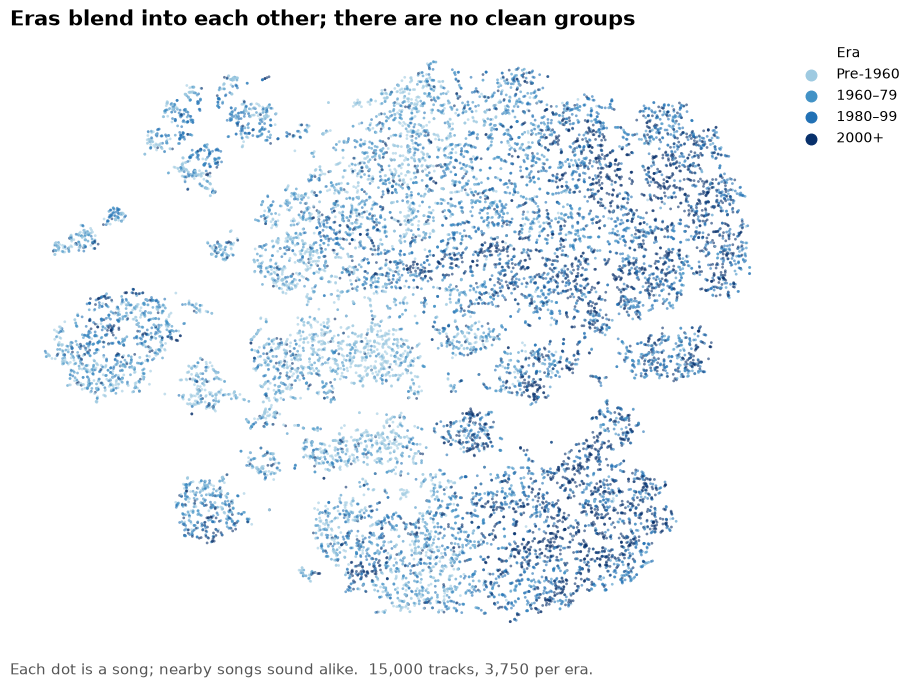

In [6]:
# Visual #2 — shuffled draw order so no era is painted on top of the others
plot = tsne.sample(frac=1, random_state=SEED)
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(plot.x, plot.y, c=plot.era.map(dict(zip(ERA_ORDER, ERA_COLORS))), s=4, alpha=0.6, linewidths=0)
for label, color in zip(ERA_LABELS, ERA_COLORS):
    ax.scatter([], [], c=color, s=40, label=label)
ax.legend(title="Era", loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, markerscale=1.2)
ax.set_title("Eras blend into each other; there are no clean groups", loc="left", fontsize=15, fontweight="bold")
ax.text(0, -0.04, "Each dot is a song; nearby songs sound alike.  15,000 tracks, 3,750 per era.",
        transform=ax.transAxes, fontsize=11, color="#555")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
fig.savefig(OUT_DIR / "fig2_tsne_era.png", dpi=200, bbox_inches="tight")
plt.show()

## 1.4 Genre-control check (report only)

Same model (LightGBM, class-weighted, default settings) and the same folds, on training tracks whose artist has a
genre tag: once with sound only, once with sound + one-hot genre family. A small gain means sound carries the
era signal on its own.

In [7]:
g = train.join(extra["primary_genre_family"], on="id").dropna(subset=["primary_genre_family"]).reset_index(drop=True)
G = pd.get_dummies(g["primary_genre_family"], prefix="genre", dtype=float)
cv_g = PredefinedSplit(g["fold"])

def gbm():
    return make_pipeline(SimpleImputer(strategy="median"),
                         LGBMClassifier(class_weight="balanced", random_state=SEED, verbose=-1))

res = {}
for label, X in {"Sound only": g[FEATURES], "Sound + genre family": pd.concat([g[FEATURES], G], axis=1)}.items():
    t0 = time.time()
    s = cross_val_score(gbm(), X, g.era, cv=cv_g, scoring="f1_macro")
    res[label] = s
    print(f"{label:<22} macro-F1 = {s.mean():.3f} ± {s.std():.3f}   ({time.time() - t0:.0f}s)")

gain = res["Sound + genre family"].mean() - res["Sound only"].mean()
print(f"\nGenre-tagged training tracks: {len(g):,} of {len(train):,} ({len(g)/len(train):.0%}); "
      f"{G.shape[1]} genre families")
print(f"Adding genre changes macro-F1 by {gain:+.3f}")
pd.DataFrame([{"features": k, "fold": i, "f1_macro": v} for k, s in res.items() for i, v in enumerate(s)]) \
  .to_csv(OUT_DIR / "genre_control.csv", index=False)

Sound only             macro-F1 = 0.591 ± 0.009   (18s)


Sound + genre family   macro-F1 = 0.616 ± 0.009   (18s)

Genre-tagged training tracks: 379,525 of 426,629 (89%); 11 genre families
Adding genre changes macro-F1 by +0.025


## 1.6 Accuracy by year (after Ashritha's `predictions.csv`, Sat 11/28)

Dips at 1960, 1980 and 2000 would show the era boundaries are fuzzy. Re-run this cell once the file exists.

In [8]:
pred_path = OUT_DIR / "predictions.csv"
if not pred_path.exists():
    print("predictions.csv not there yet; run this cell after Part 2.")
else:
    pred_df = pd.read_csv(pred_path)
    acc_by_year = pred_df.assign(ok=pred_df.pred == pred_df.era).groupby("year").ok.mean()
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(acc_by_year.index, acc_by_year.values, color=ERA_COLORS[2], lw=2)
    for b, c in zip([1960, 1980, 2000], ERA_COLORS[1:]):
        ax.axvline(b - 0.5, color=c, ls="--", lw=1)
    ax.set_ylabel("Test accuracy"); ax.set_xlabel("Release year")
    ax.set_title("Accuracy dips at the era boundaries", loc="left", fontweight="bold")
    fig.savefig(OUT_DIR / "fig_accuracy_by_year.png", dpi=200, bbox_inches="tight")
    plt.show()

predictions.csv not there yet; run this cell after Part 2.
